<a href="https://colab.research.google.com/github/febyataalya/PCVK-Ganjil-2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TUGAS PRAKTIKUM**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

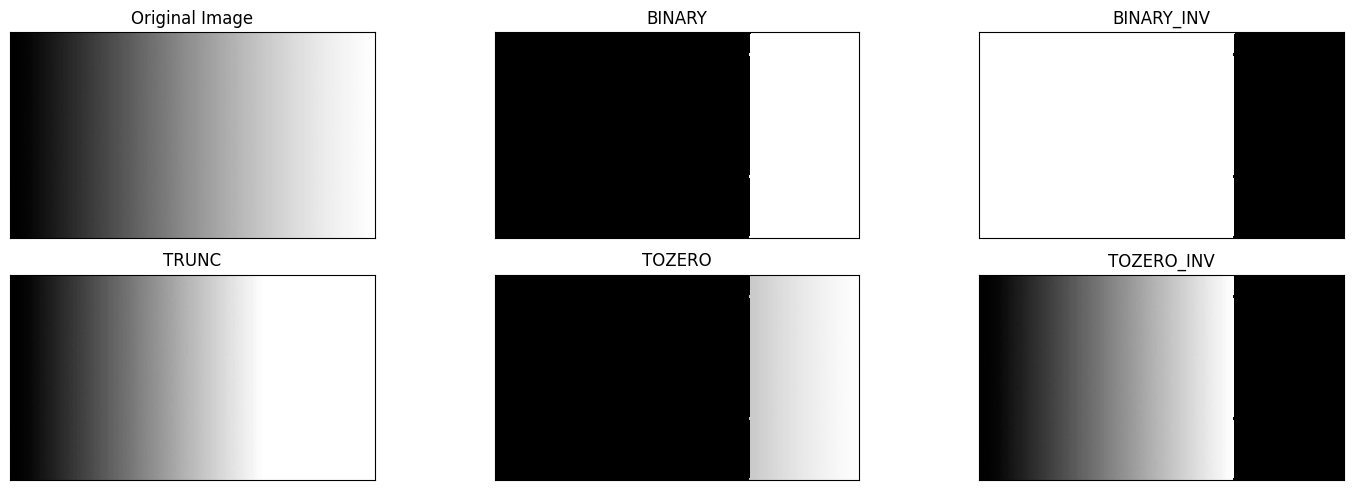

In [3]:
# 1. Baca citra dalam mode grayscale (pastikan path file sesuai di Google Drive Anda)
filename = '/content/drive/MyDrive/PCVK 2026/Images/gradient.jpg'
img = cv.imread(filename, 0)

# Tentukan nilai threshold dan nilai maksimal
thresh = 200
maxval = 255

# 2. Implementasi Global Thresholding secara Manual

# A. BINARY: > thresh menjadi maxval (255), lainnya menjadi 0
img_binary = np.where(img > thresh, maxval, 0).astype(np.uint8)

# B. BINARY_INV: > thresh menjadi 0, lainnya menjadi maxval (255)
img_binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)

# C. TRUNC: > thresh menjadi nilai thresh (200), lainnya nilai asli tetap
img_trunc = np.where(img > thresh, thresh, img).astype(np.uint8)

# D. TOZERO: > thresh nilai asli tetap, lainnya menjadi 0
img_tozero = np.where(img > thresh, img, 0).astype(np.uint8)

# E. TOZERO_INV: > thresh menjadi 0, lainnya nilai asli tetap
img_tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

# 3. Menampilkan Hasil Plotting dalam Grid 2x3
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, img_binary, img_binary_inv, img_trunc, img_tozero, img_tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

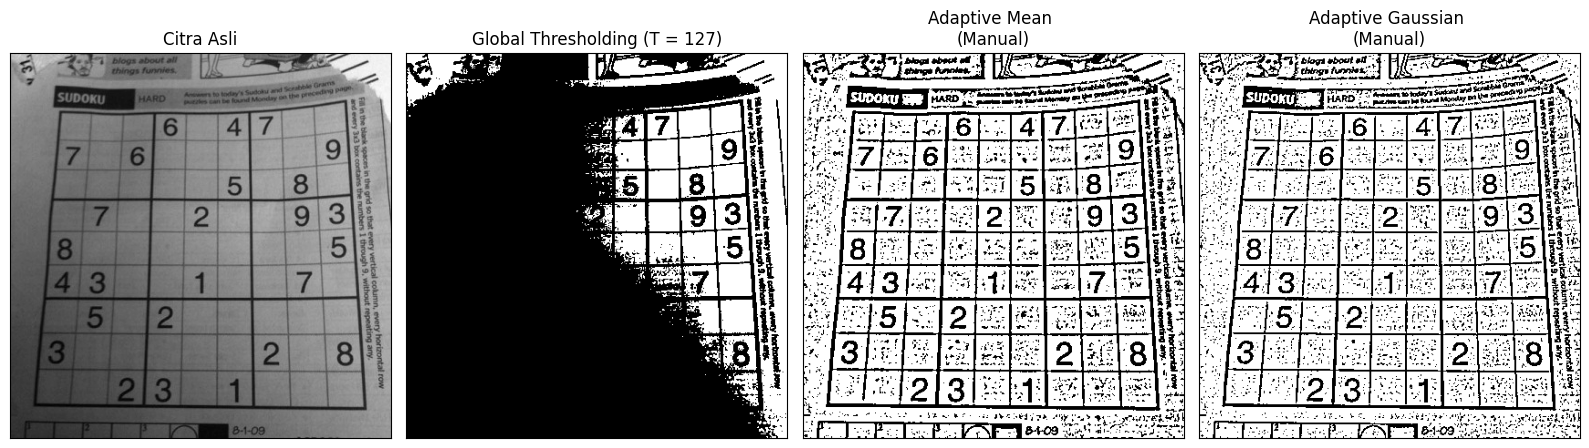

In [4]:
# 1. Baca citra Sudoku dalam mode grayscale (pastikan path sesuai di Google Drive)
filename = '/content/drive/MyDrive/PCVK 2026/Images/sudoku-original.jpg'
img = cv.imread(filename, 0)

if img is None:
    print(f"Error: Gagal membaca citra dari {filename}. Periksa kembali path file Anda!")
else:
    # 2. Global Thresholding secara Manual (T = 127)
    global_thresh = 127
    global_img = np.where(img > global_thresh, 255, 0).astype(np.uint8)

    # 3. Fungsi Manual untuk Adaptive Threshold (Mean & Gaussian) tanpa fungsi siap pakai
    def manual_adaptive_threshold(gray_img, block_size=11, C=2, method='mean', sigma=2):
        pad_len = block_size // 2
        # Padding citra menggunakan replikasi tepi (edge)
        padded = np.pad(gray_img, pad_len, mode='edge')
        H, W = gray_img.shape
        out = np.zeros((H, W), dtype=np.uint8)

        # Buat kernel Gaussian jika metodenya 'gaussian'
        if method == 'gaussian':
            ax = np.arange(-pad_len, pad_len + 1)
            xx, yy = np.meshgrid(ax, ax)
            kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
            kernel = kernel / np.sum(kernel) # Normalisasi bobot kernel agar jumlahnya 1

        # Iterasi melalui setiap piksel citra
        for i in range(H):
            for j in range(W):
                window = padded[i:i+block_size, j:j+block_size]

                if method == 'mean':
                    T = np.mean(window) - C
                elif method == 'gaussian':
                    T = np.sum(window * kernel) - C

                # Perbandingan piksel terhadap ambang batas lokal T(x,y)
                if gray_img[i, j] > T:
                    out[i, j] = 255
                else:
                    out[i, j] = 0

        return out

    # Eksekusi Adaptive Mean dan Adaptive Gaussian manual sesuai ketentuan modul
    adaptive_mean = manual_adaptive_threshold(img, block_size=11, C=2, method='mean')
    adaptive_gauss = manual_adaptive_threshold(img, block_size=11, C=2, method='gaussian', sigma=2)

    # 4. Plotting hasil perbandingan dalam 1 baris (4 kolom)
    titles = [
        'Citra Asli',
        'Global Thresholding (T = 127)',
        'Adaptive Mean \n(Manual)',
        'Adaptive Gaussian \n(Manual)'
    ]
    images = [img, global_img, adaptive_mean, adaptive_gauss]

    plt.figure(figsize=(16, 5))
    for i in range(len(images)):
        plt.subplot(1, 4, i + 1)
        plt.imshow(images[i], 'gray')
        plt.title(titles[i])
        plt.xticks([]), plt.yticks([])

    plt.tight_layout()
    plt.show()

93


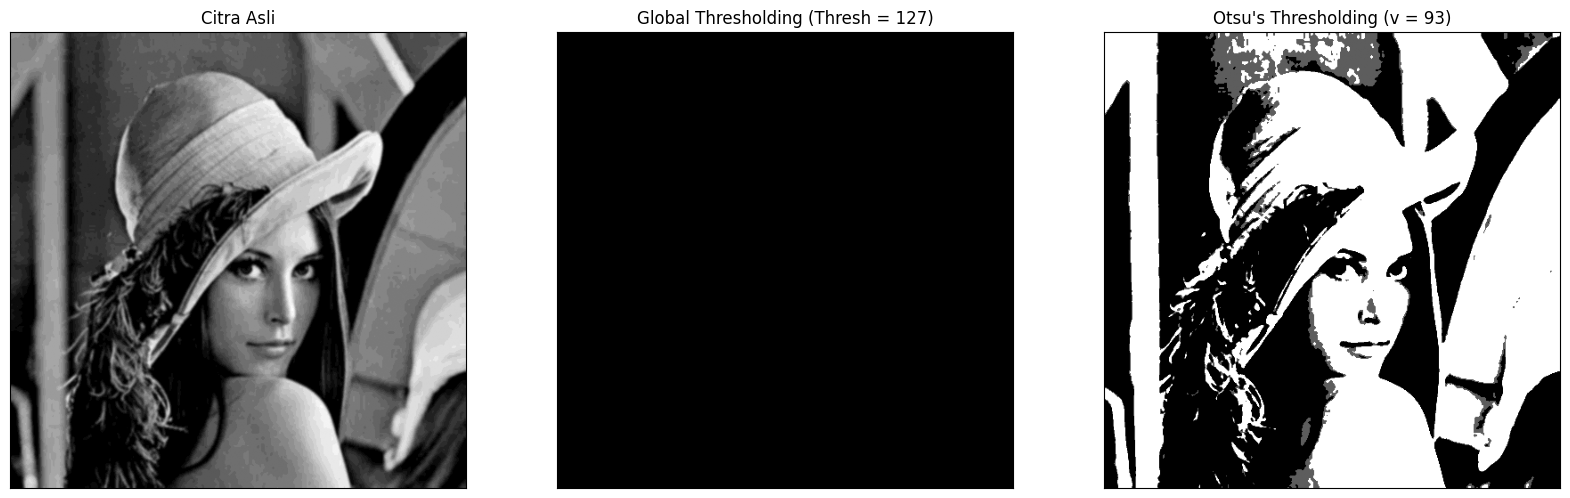

In [5]:
filename = ('/content/drive/MyDrive/PCVK 2026/Images/lena_gs_lc2.jpg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.show()

Seed (baris, kolom): (36, 43) | Intensitas: 159


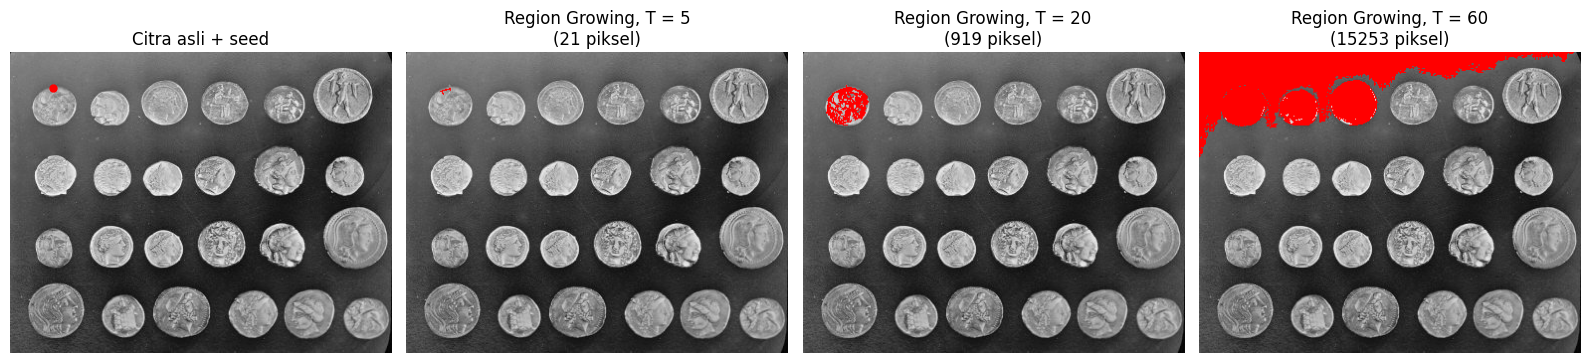

In [6]:
# 1. Muat citra koin grayscale dari skimage (ukuran 303 x 384)
gray = data.coins()

# 2. Tentukan titik seed (baris, kolom) di dalam salah satu koin
seed = (36, 43)
intensity = gray[seed]
print(f"Seed (baris, kolom): {seed} | Intensitas: {intensity}")

# 3. Jalankan segmentasi flood dengan nilai toleransi (T) 5, 20, dan 60
tolerances = [5, 20, 60]
results = []

for t in tolerances:
    # Menggunakan fungsi flood dengan connectivity=1 (4 tetangga untuk citra 2D)
    mask = flood(gray, seed_point=seed, tolerance=t, connectivity=1)
    results.append(mask)

# 4. Tampilkan hasil visualisasi dalam bentuk grid
plt.figure(figsize=(16, 4))

# Subplot 1: Citra Asli + Titik Seed (ditandai titik merah)
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'ro', markersize=5)
plt.title('Citra asli + seed')
plt.axis('off')

# Subplot 2-4: Hasil Region Growing dengan T = 5, 20, dan 60
titles = [f'Region Growing, T = {t}\n({np.sum(m)} piksel)' for t, m in zip(tolerances, results)]
for i, m in enumerate(results):
    plt.subplot(1, 4, i + 2)
    # Membuat overlay warna merah pada piksel yang masuk ke dalam mask region
    overlay = np.stack([gray, gray, gray], axis=-1)
    overlay[m] = [255, 0, 0]
    plt.imshow(overlay)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Seed (baris, kolom): (121, 63) | Intensitas: 224


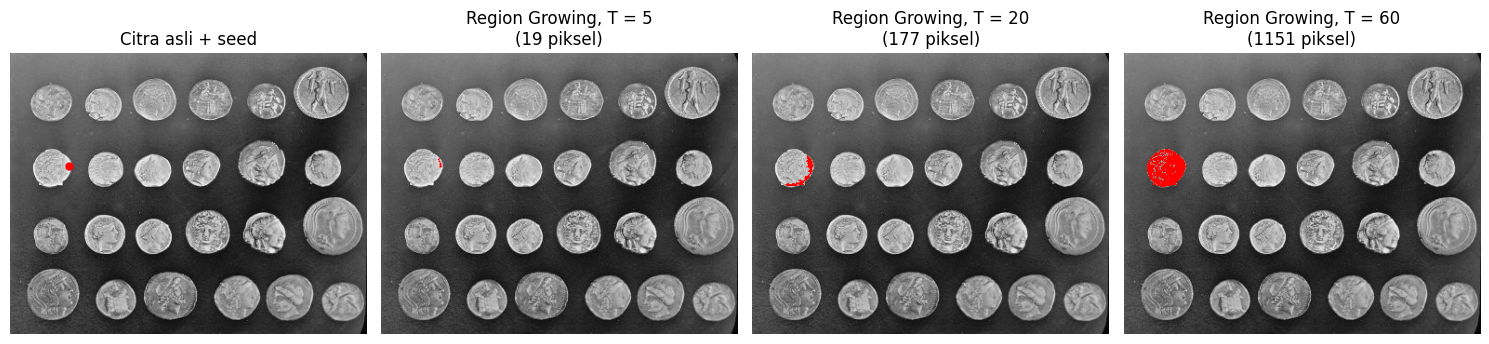

In [7]:
# 1. Memuat citra koin grayscale dari skimage
gray = data.coins()

# 2. Menentukan titik seed (baris, kolom) sesuai contoh modul
seed = (121, 63)  # atau (36, 43) seperti pada ilustrasi hasil
intensity = gray[seed]
print(f"Seed (baris, kolom): {seed} | Intensitas: {intensity}")

# 3. Daftar nilai toleransi yang diuji (T = 5, 20, dan 60)
tolerances = [5, 20, 60]
results = []

for t in tolerances:
    # Menggunakan fungsi flood dengan connectivity=1 (4 tetangga untuk citra 2D)
    mask = flood(gray, seed_point=seed, tolerance=t, connectivity=1)
    results.append(mask)

# 4. Menampilkan hasil visualisasi dalam bentuk grid
plt.figure(figsize=(15, 4))

# Plot 1: Citra asli + titik seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'ro', markersize=5)
plt.title('Citra asli + seed')
plt.axis('off')

# Plot 2-4: Hasil Region Growing dengan T = 5, 20, dan 60
for i, t in enumerate(tolerances):
    plt.subplot(1, 4, i + 2)
    # Membuat overlay warna merah pada area region yang terdeteksi
    overlay = np.stack([gray, gray, gray], axis=-1)
    overlay[results[i]] = [255, 0, 0]
    num_pixels = np.sum(results[i])
    plt.imshow(overlay)
    plt.title(f'Region Growing, T = {t}\n({num_pixels} piksel)')
    plt.axis('off')

plt.tight_layout()
plt.show()

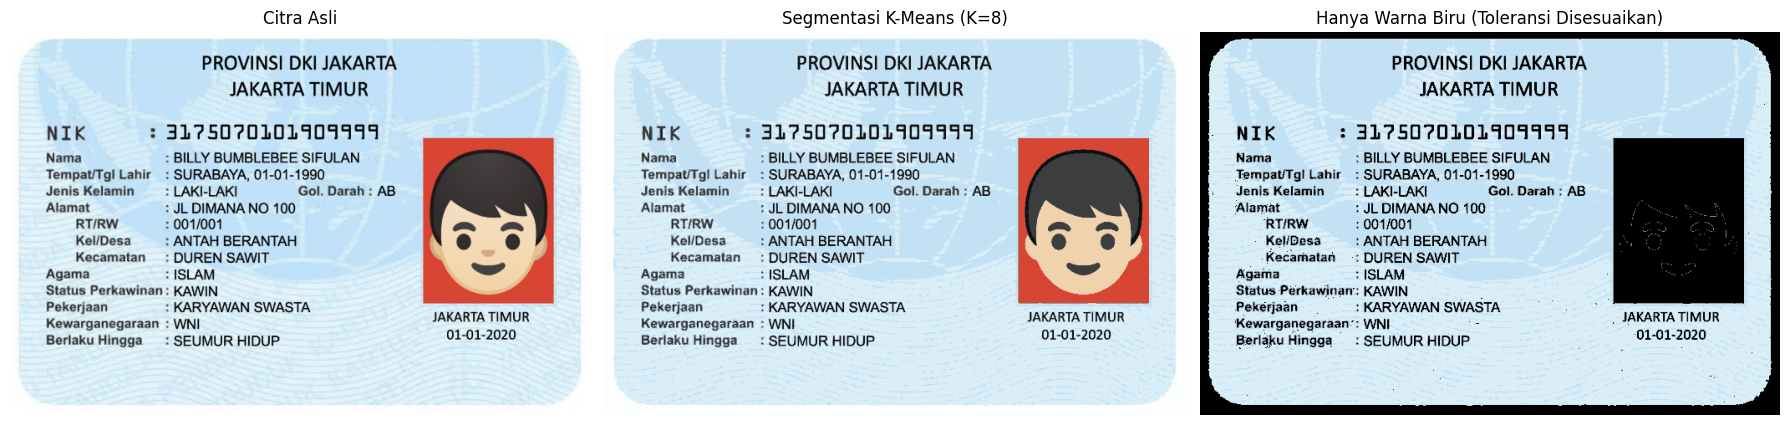

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage import color

# 1. Memuat citra dari Google Drive
filename = '/content/drive/MyDrive/PCVK 2026/Images/ktp_fulan.jpg'
citra_asli = cv2.imread(filename)

if citra_asli is None:
    filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
    citra_asli = cv2.imread(filename)

citra_asli_rgb = cv2.cvtColor(citra_asli, cv2.COLOR_BGR2RGB)

# 2. Segmentasi K-Means (K=8)
rows, cols, ch = citra_asli_rgb.shape
pixels = citra_asli_rgb.reshape(-1, ch)

kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans.fit(pixels)
segmented_colors = kmeans.cluster_centers_[kmeans.labels_]
citra_kmeans = segmented_colors.reshape(rows, cols, ch).astype(np.uint8)

# 3. Konversi hasil K-Means ke ruang warna HSV (skala 0-1)
citra_hsv = color.rgb2hsv(citra_kmeans)

# Gunakan skala 0-1 langsung agar lebih aman dari perbedaan pustaka (skimage vs OpenCV)
# Rentang Hue biru dalam skimage biasanya berada di sekitar 0.5 hingga 0.65 (ekuivalen 180°-230°)
# Atau kita gunakan rentang yang sangat longgar untuk memastikan tidak hitam:
H = citra_hsv[:, :, 0]
S = citra_hsv[:, :, 1]
V = citra_hsv[:, :, 2]

# Coba rentang alternatif yang lebih luas untuk mencakup latar KTP Anda:
# Hue 0.5 sampai 0.7 setara dengan warna Cyan/Biru
mask = (H >= 0.45) & (H <= 0.75) & (S >= 0.10) & (V >= 0.20)

# Jika mask masih kosong (semua False), gunakan cara otomatis: ambil warna latar dominan
if np.sum(mask) == 0:
    print("Mask awal kosong, memperluas rentang warna...")
    mask = (S >= 0.05) & (V >= 0.3) # Menyaring area yang memiliki warna (tidak terlalu putih/hitam)

# 4. Membuat citra akhir "Hanya Warna Biru"
hanya_biru = np.zeros_like(citra_kmeans)
hanya_biru[mask] = citra_kmeans[mask]

# 5. Menampilkan hasil
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(citra_asli_rgb)
axes[0].set_title('Citra Asli')
axes[0].axis('off')

axes[1].imshow(citra_kmeans)
axes[1].set_title('Segmentasi K-Means (K=8)')
axes[1].axis('off')

axes[2].imshow(hanya_biru)
axes[2].set_title('Hanya Warna Biru (Toleransi Disesuaikan)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

**TUGAS PRAKTIKUM KELOMPOK**